<a href="https://colab.research.google.com/github/PratikAmane05/ACV_Case_Study/blob/main/ACV_CA2_Case_Study_2_YOLO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

!pip install ultralytics


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 35.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Load pretrained YOLO26n model
model = YOLO("yolo26n.pt")

print("YOLO model loaded successfully!")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
YOLO model loaded successfully!


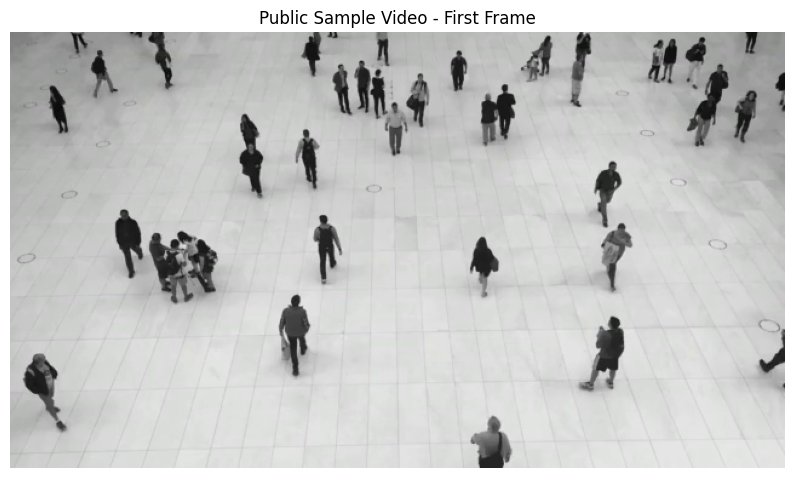

Video downloaded successfully!
Video width: 640
Video height: 360
Total frames: 62


In [ ]:

import requests
import cv2
import matplotlib.pyplot as plt

video_url = "https://github.com/ultralytics/assets/releases/download/v0.0.0/solutions_ci_demo.mp4"

response = requests.get(video_url, timeout=60)
response.raise_for_status()

with open("traffic_video.mp4", "wb") as f:
    f.write(response.content)

# Open the downloaded video
cap = cv2.VideoCapture("traffic_video.mp4")

if not cap.isOpened():
    raise ValueError("Could not open the downloaded video.")

# Read one frame
success, frame = cap.read()

if success:
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 6))
    plt.imshow(frame_rgb)
    plt.title("Public Sample Video - First Frame")
    plt.axis("off")
    plt.show()

    print("Video downloaded successfully!")
    print("Video width:", int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)))
    print("Video height:", int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
    print("Total frames:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))
else:
    print("Could not read video frame.")

cap.release()


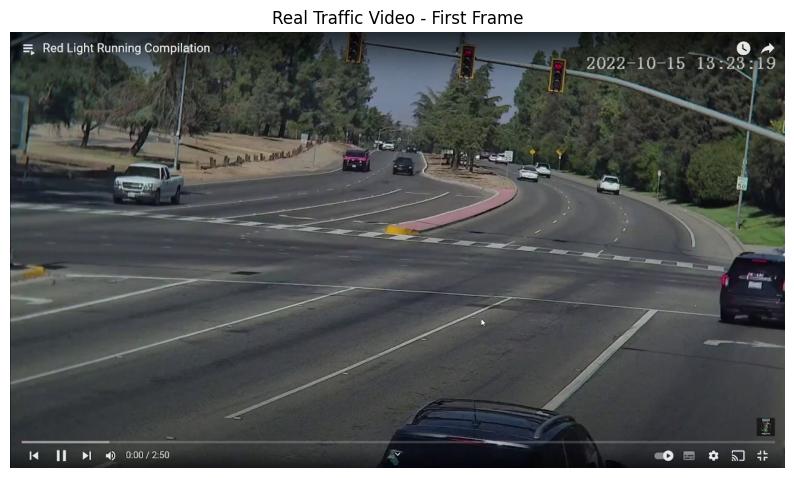

Traffic video downloaded successfully!
Resolution: 1280 x 720
Total frames: 251


In [ ]:

import requests
import cv2
import matplotlib.pyplot as plt

video_url = "https://zenodo.org/records/14041920/files/video3.mp4?download=1"

response = requests.get(video_url, timeout=120)
response.raise_for_status()

with open("traffic_video.mp4", "wb") as f:
    f.write(response.content)

cap = cv2.VideoCapture("traffic_video.mp4")

if not cap.isOpened():
    raise ValueError("Could not open traffic video.")

# Read a frame
success, frame = cap.read()

if not success:
    raise ValueError("Could not read video frame.")

frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 6))
plt.imshow(frame_rgb)
plt.title("Real Traffic Video - First Frame")
plt.axis("off")
plt.show()

print("Traffic video downloaded successfully!")
print("Resolution:",
      int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), "x",
      int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
print("Total frames:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))

cap.release()


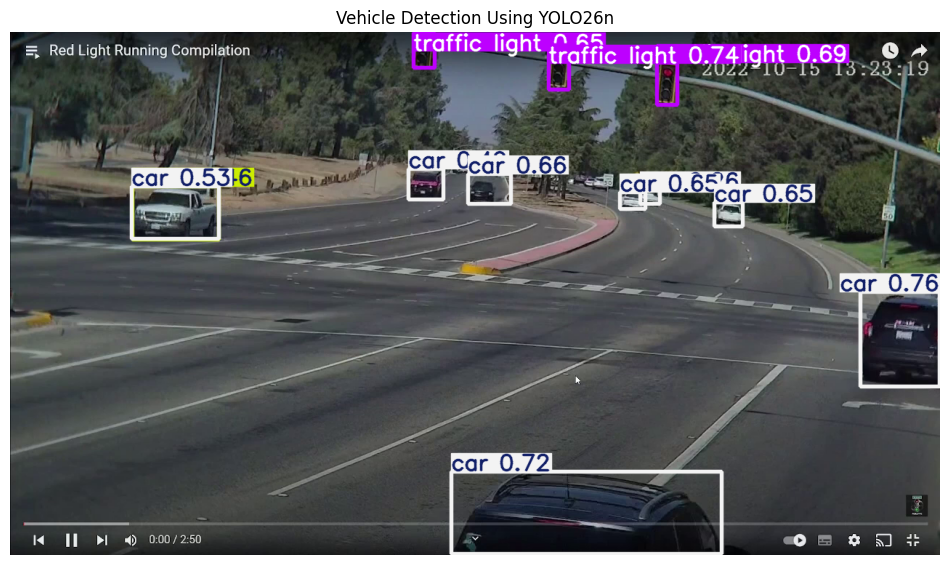

Detected objects:
car: 0.76
traffic light: 0.74
car: 0.72
traffic light: 0.69
car: 0.66
car: 0.65
car: 0.65
traffic light: 0.65
car: 0.53
car: 0.49
truck: 0.46
car: 0.26


In [ ]:

# Open traffic video
cap = cv2.VideoCapture("traffic_video.mp4")

# Read the first frame
success, frame = cap.read()

if not success:
    raise ValueError("Could not read traffic video.")

# Run YOLO detection
results = model.predict(
    source=frame,
    conf=0.25,
    verbose=False
)

# Get annotated image
annotated_frame = results[0].plot()

# Display detection result
plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB))
plt.title("Vehicle Detection Using YOLO26n")
plt.axis("off")
plt.show()

# Print detected objects
print("Detected objects:")

for box in results[0].boxes:
    class_id = int(box.cls[0])
    class_name = model.names[class_id]
    confidence = float(box.conf[0])

    print(f"{class_name}: {confidence:.2f}")

cap.release()


Video processing completed!
Total frames processed: 251

Vehicle Detection Counts:
car : 2256
motorcycle : 101
bus : 0
truck : 391


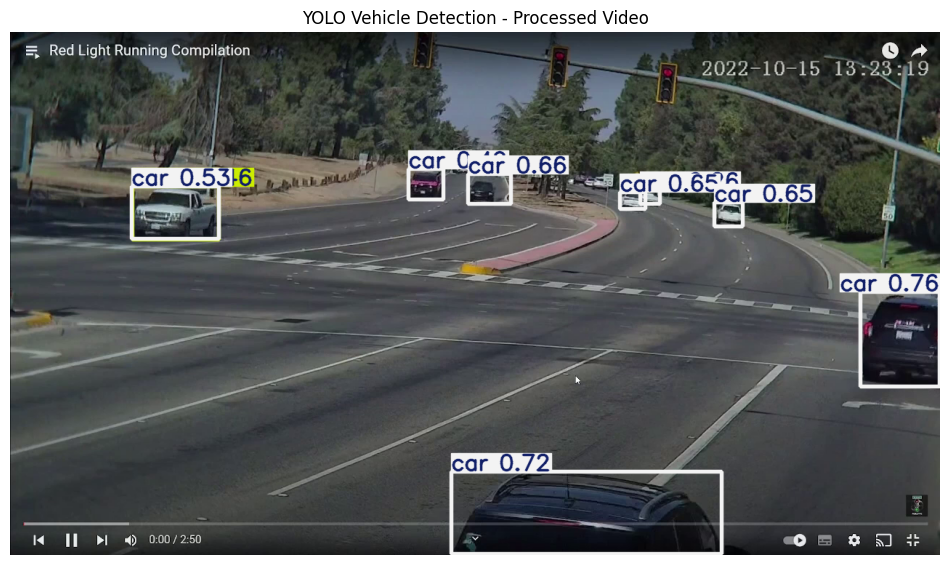


Output saved as vehicle_detection_output.mp4


In [ ]:

# Open original traffic video
cap = cv2.VideoCapture("traffic_video.mp4")

# Get video properties
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)

# Create output video
fourcc = cv2.VideoWriter_fourcc(*"mp4v")
out = cv2.VideoWriter(
    "vehicle_detection_output.mp4",
    fourcc,
    fps if fps > 0 else 25,
    (width, height)
)

# COCO vehicle class IDs
vehicle_classes = [2, 3, 5, 7]

# Count detections
vehicle_counts = {
    "car": 0,
    "motorcycle": 0,
    "bus": 0,
    "truck": 0
}

frame_count = 0
first_annotated_frame = None

while cap.isOpened():
    success, frame = cap.read()

    if not success:
        break

    # Detect only vehicles
    results = model.predict(
        frame,
        conf=0.25,
        classes=vehicle_classes,
        verbose=False
    )

    # Draw bounding boxes
    annotated = results[0].plot()

    # Count detected vehicles
    for box in results[0].boxes:
        class_id = int(box.cls[0])
        class_name = model.names[class_id]
        vehicle_counts[class_name] += 1

    if first_annotated_frame is None:
        first_annotated_frame = annotated.copy()

    out.write(annotated)
    frame_count += 1

cap.release()
out.release()

print("Video processing completed!")
print("Total frames processed:", frame_count)

print("\nVehicle Detection Counts:")
for vehicle, count in vehicle_counts.items():
    print(vehicle, ":", count)

# Display an annotated frame
plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(
    first_annotated_frame, cv2.COLOR_BGR2RGB
))
plt.title("YOLO Vehicle Detection - Processed Video")
plt.axis("off")
plt.show()

print("\nOutput saved as vehicle_detection_output.mp4")


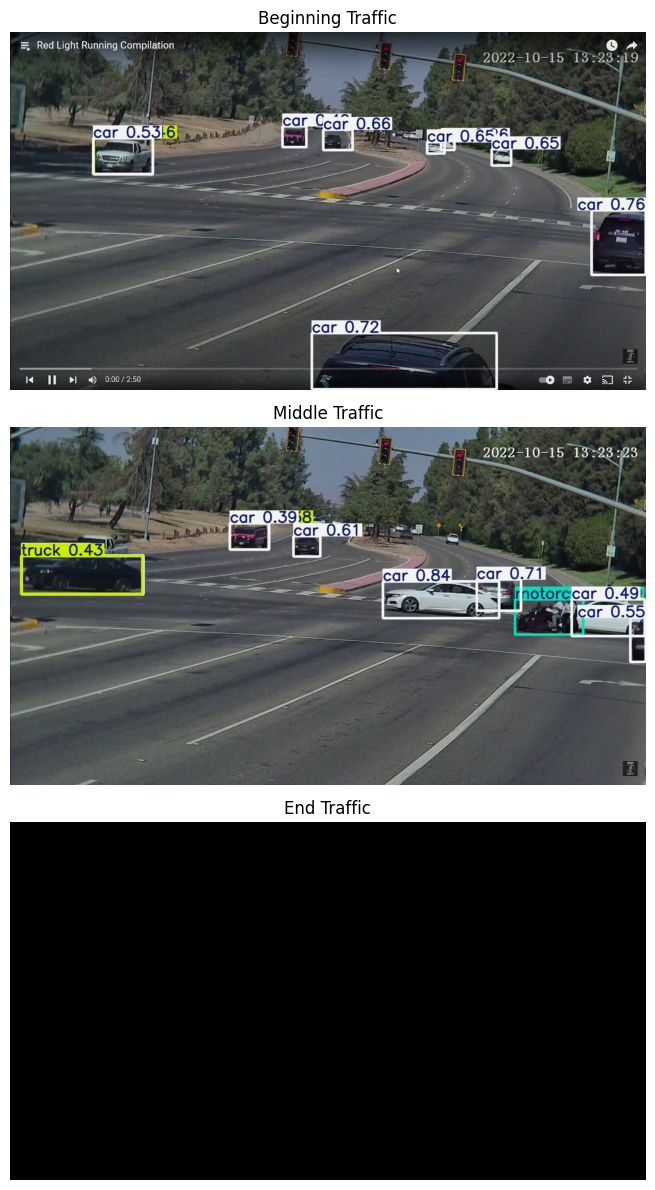

,Traffic Sample,Frame Number,Cars,Motorcycles,Buses,Trucks,Total Vehicles,Average Confidence
0,Beginning,0,8,0,0,1,9,0.576
1,Middle,125,7,1,0,2,10,0.505
2,End,250,0,0,0,0,0,0.000


In [ ]:

import pandas as pd

cap = cv2.VideoCapture("traffic_video.mp4")

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

# Select beginning, middle and end frames
positions = {
    "Beginning": 0,
    "Middle": total_frames // 2,
    "End": total_frames - 1
}

vehicle_classes = [2, 3, 5, 7]

evaluation_results = []

plt.figure(figsize=(16, 12))

for i, (condition, frame_number) in enumerate(positions.items()):

    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
    success, frame = cap.read()

    if not success:
        print("Could not read:", condition)
        continue

    # Run YOLO on selected frame
    result = model.predict(
        frame,
        conf=0.25,
        classes=vehicle_classes,
        verbose=False
    )[0]

    # Count vehicle classes and calculate average confidence
    counts = {
        "car": 0,
        "motorcycle": 0,
        "bus": 0,
        "truck": 0
    }

    confidences = []

    for box in result.boxes:
        class_name = result.names[int(box.cls[0])]
        counts[class_name] += 1
        confidences.append(float(box.conf[0]))

    total = sum(counts.values())
    avg_conf = (
        np.mean(confidences) if confidences else 0
    )

    evaluation_results.append({
        "Traffic Sample": condition,
        "Frame Number": frame_number,
        "Cars": counts["car"],
        "Motorcycles": counts["motorcycle"],
        "Buses": counts["bus"],
        "Trucks": counts["truck"],
        "Total Vehicles": total,
        "Average Confidence": round(avg_conf, 3)
    })

    # Display annotated frame
    annotated = result.plot()

    plt.subplot(3, 1, i + 1)
    plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    plt.title(condition + " Traffic")
    plt.axis("off")

cap.release()
plt.tight_layout()
plt.show()

# Display evaluation table
evaluation_df = pd.DataFrame(evaluation_results)
display(evaluation_df)


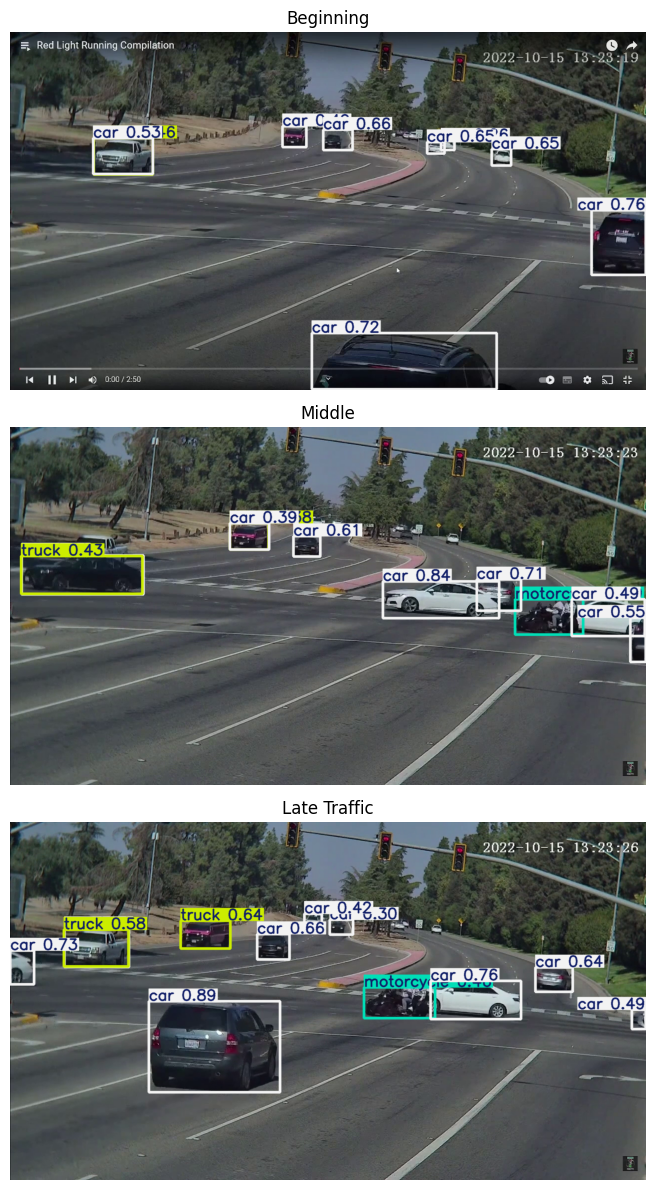

,Traffic Sample,Frame Number,Cars,Motorcycles,Buses,Trucks,Total Vehicles,Average Confidence
0,Beginning,0,8,0,0,1,9,0.576
1,Middle,125,7,1,0,2,10,0.505
2,Late Traffic,200,9,1,0,2,12,0.581


In [ ]:

cap = cv2.VideoCapture("traffic_video.mp4")

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

positions = {
    "Beginning": 0,
    "Middle": total_frames // 2,
    "Late Traffic": int(total_frames * 0.8)
}

evaluation_results = []

plt.figure(figsize=(14, 12))

for i, (condition, frame_number) in enumerate(positions.items()):

    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
    success, frame = cap.read()

    if not success:
        print("Could not read:", condition)
        continue

    result = model.predict(
        frame,
        conf=0.25,
        classes=[2, 3, 5, 7],
        verbose=False
    )[0]

    counts = {
        "car": 0, "motorcycle": 0,
        "bus": 0, "truck": 0
    }
    confidences = []

    for box in result.boxes:
        name = result.names[int(box.cls[0])]
        counts[name] += 1
        confidences.append(float(box.conf[0]))

    total = sum(counts.values())
    avg_conf = np.mean(confidences) if confidences else 0

    evaluation_results.append({
        "Traffic Sample": condition,
        "Frame Number": frame_number,
        "Cars": counts["car"],
        "Motorcycles": counts["motorcycle"],
        "Buses": counts["bus"],
        "Trucks": counts["truck"],
        "Total Vehicles": total,
        "Average Confidence": round(float(avg_conf), 3)
    })

    annotated = result.plot()

    plt.subplot(3, 1, i + 1)
    plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    plt.title(condition)
    plt.axis("off")

cap.release()
plt.tight_layout()
plt.show()

evaluation_df = pd.DataFrame(evaluation_results)
display(evaluation_df)
